# Imports

In [195]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, GroupShuffleSplit
from sklearn.metrics import roc_auc_score, average_precision_score
from typing import Literal
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import xgboost as xgb
from catboost import CatBoostClassifier
import lightgbm as lgb
import os
import warnings
from scipy.stats import ConstantInputWarning
from ds_engineer import export_dataframe
warnings.filterwarnings("ignore", category=ConstantInputWarning) # Warning from SHAP, pearson coefficient input array is intentionally constant.

# Loading Data

In [196]:
parquet_path = '../data/ds08a_rows.parquet'
parquet_df = pd.read_parquet(parquet_path)
parquet_df = parquet_df.copy().drop(columns=['split', 'raw_idx']).dropna()
print(parquet_df.columns)

Index(['alt', 'Mach', 'TRA', 'T2', 'T24', 'T30', 'T48', 'T50', 'P15', 'P2',
       'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf', 'T40', 'P30',
       'P45', 'W21', 'W22', 'W25', 'W31', 'W32', 'W48', 'W50', 'SmFan',
       'SmLPC', 'SmHPC', 'phi', 'fan_eff_mod', 'fan_flow_mod', 'LPC_eff_mod',
       'LPC_flow_mod', 'HPC_eff_mod', 'HPC_flow_mod', 'HPT_eff_mod',
       'HPT_flow_mod', 'LPT_eff_mod', 'LPT_flow_mod', 'RUL', 'unit', 'cycle',
       'Fc', 'hs', 'EPR'],
      dtype='str')


# Cleaning and Feature Engineering
  * columns are renamed  so the meaning of the senor data can be understood.
  * Inlet mass airflow is defined
  * Efficiency metrics are calculated

In [225]:
df = export_dataframe(parquet_df)
print(df.columns)

Index(['alt', 'Mach', 'throttle_resolver_angle', 'inlet_temp_tot',
       'LPC_outlet_temp_tot', 'HPC_outlet_temp_tot', 'HPT_outlet_temp_tot',
       'LPT_outlet_temp_tot', 'bypass_psia_tot', 'inlet_psia_tot',
       'fan_outlet_psia_tot', 'LPC_outlet_psia_tot', 'HPC_outlet_psia_static',
       'burner_outlet_psia_tot', 'LPT_outlet_psia_tot', 'fan_speed',
       'core_speed', 'fuel_flow', 'burner_outlet_temp_tot',
       'HPC_outlet_psia_tot', 'HPT_outlet_psia_tot', 'fan_flow_pps',
       'LPC_outflow_flow', 'HPC_inflow_flow', 'HPT_coolant_bleed_stageA_flow',
       'HPT_coolant_bleed_stageB_flow', 'HPT_outlet_flow', 'LPT_outflow',
       'SmFan', 'SmLPC', 'SmHPC', 'fuel_flow_to_HPC_outlet_psia_static_ratio',
       'fan_eff_mod', 'fan_flow_mod', 'LPC_eff_mod', 'LPC_flow_mod',
       'HPC_eff_mod', 'HPC_flow_mod', 'HPT_eff_mod', 'HPT_flow_mod',
       'LPT_eff_mod', 'LPT_flow_mod', 'RUL', 'unit', 'cycle', 'flight_cond',
       'health_status', 'EPR', 'inlet_maf', 'fan_flow_eff', 'fan_p

# Preprocessing
* Splitting was done by engine unit to prevent data leakage

In [201]:
def preprocess_tree(df, label:str, threshold=0.0, leak_check = False):
    df = df.reset_index(drop=True)

    groups = df["unit"].to_numpy()
    y = (df[label] > threshold).astype(int).to_numpy()

    if leak_check:
      health_params = ['fan_eff_mod','fan_flow_mod','LPC_eff_mod','LPC_flow_mod',
                       'HPC_eff_mod','HPC_flow_mod','HPT_eff_mod','HPT_flow_mod',
                       'LPT_eff_mod','LPT_flow_mod']

      x = df.drop(columns=["unit", "cycle", "health_status", "RUL"] + health_params)

    if not leak_check:
      x = df.drop(columns=["unit", "cycle", "health_status", 'RUL'])

    def split_units(idx, test_size):
        '''Split row indices so every engine unit lands in exactly one side.'''
        gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=42)
        tr, te = next(gss.split(idx, groups=groups[idx]))
        return idx[tr], idx[te]

    # 80% trainval / 20% test, then 80% train / 20% val (by unit)
    trainval, test = split_units(np.arange(len(df)), 0.2)
    train, val = split_units(trainval, 0.2)

    xtrain, ytrain, gtrain = x.iloc[trainval], y[trainval], groups[trainval]
    xtest,  ytest          = x.iloc[test],     y[test]
    xtr,    ytr            = x.iloc[train],    y[train]
    xval,   yval           = x.iloc[val],      y[val]

    return xtrain, xtest, ytrain, ytest, xtr, xval, ytr, yval, gtrain

# Models
* Tree ensemble models are defined below
* The _get_best_trees helper function finds the iteration hyperparameter

In [202]:
def _tree_models(model_string: str, n_estimators = 200, early_stopping = None):
    '''
    Build the model based upon the string passed
    Input: string
    Output: tree based ensemble
    '''

    if model_string == "XGBoost":
        return xgb.XGBClassifier(
            n_estimators=n_estimators, learning_rate=0.1,
            tree_method="hist", objective="binary:logistic", eval_metric="auc",
            early_stopping_rounds=early_stopping, n_jobs=4, random_state=42,
        )
    if model_string == "LightGBM":
        return lgb.LGBMClassifier(
            n_estimators=n_estimators, learning_rate=0.1,
            n_jobs=4, random_state=42, verbose=-1,
        )
    if model_string == "CatBoost":
        return CatBoostClassifier(
            n_estimators=n_estimators, learning_rate=0.1,
            eval_metric="AUC", early_stopping_rounds=early_stopping,
            thread_count=4, random_seed=42, verbose=0,
        )
    raise ValueError(f"model string '{model_string}' not recognized ")


def _get_best_trees(model_string: str, xtr, ytr, xval, yval):
    '''
    Train regularized validations set
    Input: Model string, split data
    Output: best tree count
    '''
    model = _tree_models(model_string, n_estimators= 2000, early_stopping=50)

    if model_string == "XGBoost":
        model.fit(xtr, ytr, eval_set=[(xval, yval)], verbose=False)
        return model.best_iteration + 1

    if model_string == "LightGBM":
        model.fit(xtr, ytr,
                  eval_X=xval,
                  eval_y=yval,
                  eval_metric="auc",
                  callbacks=[lgb.early_stopping(50, verbose=False)]) # eval_set=[(xval, yval)],
        return model.best_iteration_

    # CatBoost
    model.fit(xtr, ytr, eval_set=(xval, yval))
    return model.get_best_iteration() + 1

# Optional saving
* Saving the models made comparing the changes easier

In [203]:
def save(model, model_string: str, path):
    '''
    Save model if desired
    Input: Trained model, name of model, path to save
    Output: model file
    '''
    if model_string == "LightGBM":
        model.booster_.save_model(path)
    else:
        model.save_model(path)

# Optional loading

In [204]:
def load(model_string: str, path):
    '''Load a saved model. Returns None if the file doesn't exist.'''
    if not os.path.exists(path):
        return None
    if model_string == "XGBoost":
        m = xgb.XGBClassifier()
        m.load_model(path)
        return m
    if model_string == "CatBoost":
        m = CatBoostClassifier()
        m.load_model(path)
        return m
    if model_string == "LightGBM":
        return lgb.Booster(model_file=path)
    raise ValueError(f"model string '{model_string}' not recognized")


def predict_proba_pos(model, x):
    '''LightGBM Boosters have no predict_proba; their predict() returns probabilities.'''
    if isinstance(model, lgb.Booster):
        return model.predict(x)
    return model.predict_proba(x)[:, 1]

# Pipeline exeution
* The functionality is explained in the docstring
* The save logic is patched from hyperparameter tuning. Many models were run, including models built on section specific data. Making options to name the models according to the section(s) proved helpful to stay organized.

In [205]:
def tree_based_ensemble(df, label, model_name: Literal["XGBoost", "LightGBM", "CatBoost"] = "XGBoost", retrain=False, leak_check = False):
    '''
    Training handler: run preprocessing -- run one of two modes

    Two modes:
    Mode 1: Load models
    Mode 2: Train models
      Phase 1: Train New
      Phase 2: Retrain
      Phase 3: Score
      Phase 4: Save
    '''

    xtrain, xtest, ytrain, ytest, xtr, xval, ytr, yval, gtrain = preprocess_tree(df, label, leak_check=leak_check)

    # Check for saved model, optionally retrain
    save_path = f'{label}{model_name}model.json'
    model = None if retrain else load(model_name, save_path)

    if model is not None:
      print(f"{model_name}: loaded {save_path}, skipping training")
      cv_scores = None

    else:
      n_trees = _get_best_trees(model_name, xtr, ytr, xval, yval)
      model = _tree_models(model_name, n_estimators=n_trees)

      folds = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
      cv = cross_validate(model, xtrain, ytrain, groups=gtrain, cv=folds,
                            scoring="average_precision")
      cv_scores = cv["test_score"]

      model.fit(xtrain, ytrain)
      save(model, model_name, save_path)
      print(f"{model_name} saved as {save_path}")

    yprob = predict_proba_pos(model, xtest)
    test_auc = average_precision_score(ytest, yprob)
    roc_auc = roc_auc_score(ytest, yprob)
    print(f"{model_name} | Test PR_AUC={test_auc:.4f} | Test ROC_AUC={roc_auc:.4f}")

    return {"model": model, "cv_scores": cv_scores,
            "yprob": yprob, "ytest": ytest, "test_auc": test_auc}


print(f'The number of columns trained on {len(df.columns)}')

tree_based_ensemble(df, 'health_status')
tree_based_ensemble(df, 'health_status', 'LightGBM')
tree_based_ensemble(df, 'health_status', 'CatBoost')

# These are retrained here because they are retrained later to check for leaks
tree_based_ensemble(df, 'RUL', retrain=True)
tree_based_ensemble(df, 'RUL', 'LightGBM', retrain=True)
tree_based_ensemble(df, 'RUL', 'CatBoost', retrain=True)

The number of columns trained on 59
XGBoost: loaded health_statusXGBoostmodel.json, skipping training
XGBoost | Test PR_AUC=0.9320 | Test ROC_AUC=0.9639
LightGBM: loaded health_statusLightGBMmodel.json, skipping training
LightGBM | Test PR_AUC=0.7632 | Test ROC_AUC=0.8776
CatBoost: loaded health_statusCatBoostmodel.json, skipping training
CatBoost | Test PR_AUC=0.9266 | Test ROC_AUC=0.9538
XGBoost saved as RULXGBoostmodel.json
XGBoost | Test PR_AUC=0.9899 | Test ROC_AUC=0.5380
LightGBM saved as RULLightGBMmodel.json
LightGBM | Test PR_AUC=0.9884 | Test ROC_AUC=0.5899
CatBoost saved as RULCatBoostmodel.json
CatBoost | Test PR_AUC=0.9992 | Test ROC_AUC=0.9498


{'model': CatBoostClassifier(eval_metric='AUC', learning_rate=0.1, n_estimators=74, random_seed=42, thread_count=4, verbose=0),
 'cv_scores': array([0.99895303, 0.99891997, 0.99902588, 0.99961794]),
 'yprob': array([0.99998804, 0.99998804, 0.99999379, ..., 0.99673539, 0.99673539,
        0.99658712], shape=(13374,)),
 'ytest': array([1, 1, 1, ..., 0, 0, 0], shape=(13374,)),
 'test_auc': 0.999245029290541}

# Analysis Functions
* get_failed sets up the SHapley Additive exPlanation(SHAP) values to establish feature importance.
* Load models to run through other functions for analysis using SHAP value
* get_failed sets up the SHapley Additive exPlanation(SHAP) values to establish feature importance.
* The function to assemble all SHAP tables (Used to make a barplot and a consensus table)

In [206]:
# get_failed sets up the SHapley Additive exPlanation(SHAP) values to establish feature importance.

def get_failed(df, label):
    '''
    Run preprocessing, training or load a model.
    '''
    xtrain, xtest, ytrain, ytest, xtr, xval, ytr, yval, _ = preprocess_tree(df, label)

    # XGBoost
    xgb_model = xgb.XGBClassifier()
    xgb_model.load_model(f"{label}XGBoostmodel.json")

    # Catboost
    cb_model = CatBoostClassifier()
    cb_model.load_model(f"{label}CatBoostmodel.json")

    # LightGBM
    booster = lgb.Booster(model_file=f"{label}LightGBMmodel.json")
    booster.predict(xtest)  # returns probabilities for binary models
    booster.feature_importance(importance_type="gain")
    booster.feature_name()

    XG_explained = shap.TreeExplainer(xgb_model).shap_values(xtest)
    Cat_explained = shap.TreeExplainer(cb_model).shap_values(xtest)

    return XG_explained

In [207]:
# Load models to run through other functions for analysis using SHAP values

fail = 0
top = 15

# Loading models for explanation
def models(choice='health_status'):
    models = {}

    if choice.lower() == 'health_status':
      xtrain, xtest, ytrain, ytest, xtr, xval, ytr, yval, gtrain = preprocess_tree(df, choice)

      models["XGBoost"] = xgb.XGBClassifier()
      models["XGBoost"].load_model(f"{choice}XGBoostmodel.json")

      models["CatBoost"] = CatBoostClassifier()
      models["CatBoost"].load_model(f"{choice}CatBoostmodel.json")

      models["LightGBM"] = lgb.Booster(model_file=f"{choice}LightGBMmodel.json")

    else:
      xtrain, xtest, ytrain, ytest, xtr, xval, ytr, yval, gtrain = preprocess_tree(df, choice)

      models["XGBoost"] = xgb.XGBClassifier()
      models["XGBoost"].load_model(f"{choice}XGBoostmodel.json")

      models["CatBoost"] = CatBoostClassifier()
      models["CatBoost"].load_model(f"{choice}CatBoostmodel.json")

      models["LightGBM"] = lgb.Booster(model_file=f"{choice}LightGBMmodel.json")

    return xtrain, xtest, ytrain, ytest, xtr, xval, ytr, yval, gtrain, models

In [208]:
# get_failed sets up the SHapley Additive exPlanation(SHAP) values to establish feature importance.
_, _, _, _, _, _, _, _, _, hs_models = models()
_, _, _, _, _, _, _, _, _, rul_models = models('RUL')

def _to_2d_shap(shap_vals, X, positive_class=0.0):
    """Return SHAP values as (n_samples, n_features).
    addressing the warning: 'TreeExplainer shap values output has changed to a list of ndarray'
    """
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[positive_class]
    elif shap_vals.ndim == 3:
        shap_vals = shap_vals[:, :, positive_class]
    assert shap_vals.shape == X.shape, f"Unexpected SHAP shape {shap_vals.shape}"
    return shap_vals

def failure_shap_table(model, xtest, ytest, fail=fail):
    '''
    SHAP (SHapley Additive exPlanations) is a game theoretic approach to explain the output of machine learning models.
    https://shap.readthedocs.io/en/latest/index.html
    SHAP values represent a feature’s responsibility for a change in the model output.
    correlation: + means high feature values drive failure, - means low values do
    mean: net influence toward failure on failed rows
    mean absolute value: influence magnitude

    '''

    explainer = shap.TreeExplainer(model)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")
        raw = explainer.shap_values(xtest)

    shap_vals = _to_2d_shap(raw, xtest)
    if fail == 0.0:
        shap_vals = -shap_vals  # Class 1 (healthy)
                                # Class 0 (not healthy)
                                # positive prediction class = toward failure (class 0)

    # This masking causes a warning with the spearman correlation coefficient in sklearn
    # SHAP drops the resultant nan values anyway, so I don't think this is a problem.
    mask = np.asarray(ytest) == fail
    shap_val_fails, X_val_fail = shap_vals[mask], xtest[mask]

    shap_df = pd.DataFrame(shap_val_fails, columns=xtest.columns)
    X_fail = X_val_fail.reset_index(drop=True)

    value_corr = [X_fail[col].corr(shap_df[col], method="spearman") for col in xtest.columns]

    table = pd.DataFrame(
        {"mean_shap": shap_df.mean(),  # net push toward failure on failed rows
                "mean_abs_shap": shap_df.abs().mean(),  # overall magnitude
                "value_corr": value_corr,  # + high values drive failure
            }, index=xtest.columns)

    return table.sort_values("mean_shap", ascending=False), shap_vals, mask

In [209]:
# The function to assemble all SHAP tables.
def get_shap_tables(X, y, models):
    '''
    Iterate through models and apply the shap table
    Input: x, y
    Output: Summary table of shap metrics
    '''
    results = {n: failure_shap_table(m, X, y) for n, m in models.items()}
    tables = {n: r[0] for n, r in results.items()}
    svals = {n: r[1] for n, r in results.items()}
    mask = next(iter(results.values()))[2]

    return tables, svals, mask

In [210]:
def get_barplots(tables):
    '''
    Iterate through models and apply the shap table
    Build a horizontal barplot for each model
    '''
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for ax, (name, t) in zip(axes, tables.items()):
        t["mean_shap"].head(top).sort_values().plot.barh(ax=ax)
        ax.set_title(name)
        ax.set_xlabel("Mean SHAP on failed rows (toward failure)")
    plt.tight_layout()
    plt.show()

In [211]:
def consensus_table(tables):
    '''
    Iterate through models and apply the shap table
    Return a summary table of all models, rankings of features, and average rank
    '''

    ranks = pd.DataFrame({n: t["mean_shap"].rank(ascending=False) for n, t in tables.items()})
    ranks["avg_rank"] = ranks.mean(axis=1)
    return ranks.sort_values("avg_rank").head(top)

In [212]:
def show_beeswarm(svals, x, mask):
    '''
    Beeswarm is sorted by the sum of SHAP value magnitudes, and shows the distribution of impacts.
    beeswarm per model for failed rows
    saves figure
    '''

    fig, axes = plt.subplots(1, len(svals), figsize=(6 * len(svals), 7))
    for ax, (name, sv) in zip(np.atleast_1d(axes), svals.items()):
        expl = shap.Explanation(
            values=sv[mask],
            data=x[mask].values,
            feature_names=list(x.columns),
        )
        shap.plots.beeswarm(expl, max_display=top, ax=ax, plot_size=None, show=False)
        ax.set_title(name)
    plt.tight_layout()
    # optionally saved
    #fig.savefig('supervised_tree_beeswarm', dpi=150, bbox_inches="tight")
    plt.show()

# Analysis
## Health Status
* Table creation
* Barplot of the most important features
* Consensus table of the most important features
* The beeswarm visualization
## Remaining Useful Life (RUL)
* Table creation
* Barplot of the most important features
* Consensus table of the most important features
* The beeswarm visualization
## Feature Ablation on RUL

# SHAP tables for health status

In [213]:
xtrain, xtest, ytrain, ytest, xtr, xval, ytr, yval, gtrain, hs_models = models()

tables, svals, mask = get_shap_tables(xtest, ytest, hs_models)

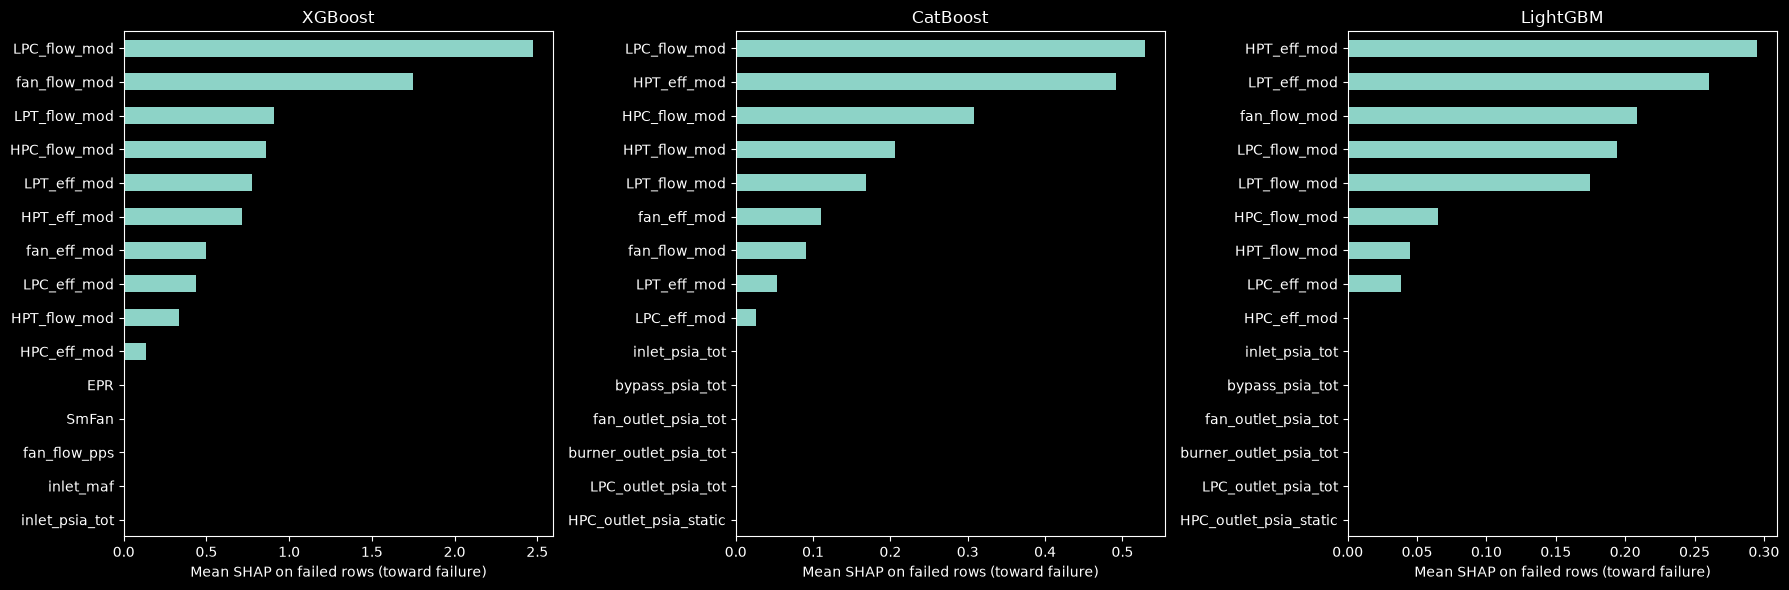

In [214]:
bar_plt = get_barplots(tables)

In [215]:
consensus_table_obj = consensus_table(tables)
consensus_df = pd.DataFrame(consensus_table_obj)
consensus_df

,XGBoost,CatBoost,LightGBM,avg_rank
LPC_flow_mod,1.0,1.0,4.0,2.000000
HPT_eff_mod,6.0,2.0,1.0,3.000000
fan_flow_mod,2.0,7.0,3.0,4.000000
HPC_flow_mod,4.0,3.0,6.0,4.333333
LPT_flow_mod,3.0,5.0,5.0,4.333333
LPT_eff_mod,5.0,8.0,2.0,5.000000
HPT_flow_mod,9.0,4.0,7.0,6.666667
LPC_eff_mod,8.0,9.0,8.0,8.333333
fan_eff_mod,7.0,6.0,55.0,22.666667
HPC_eff_mod,10.0,55.0,9.0,24.666667


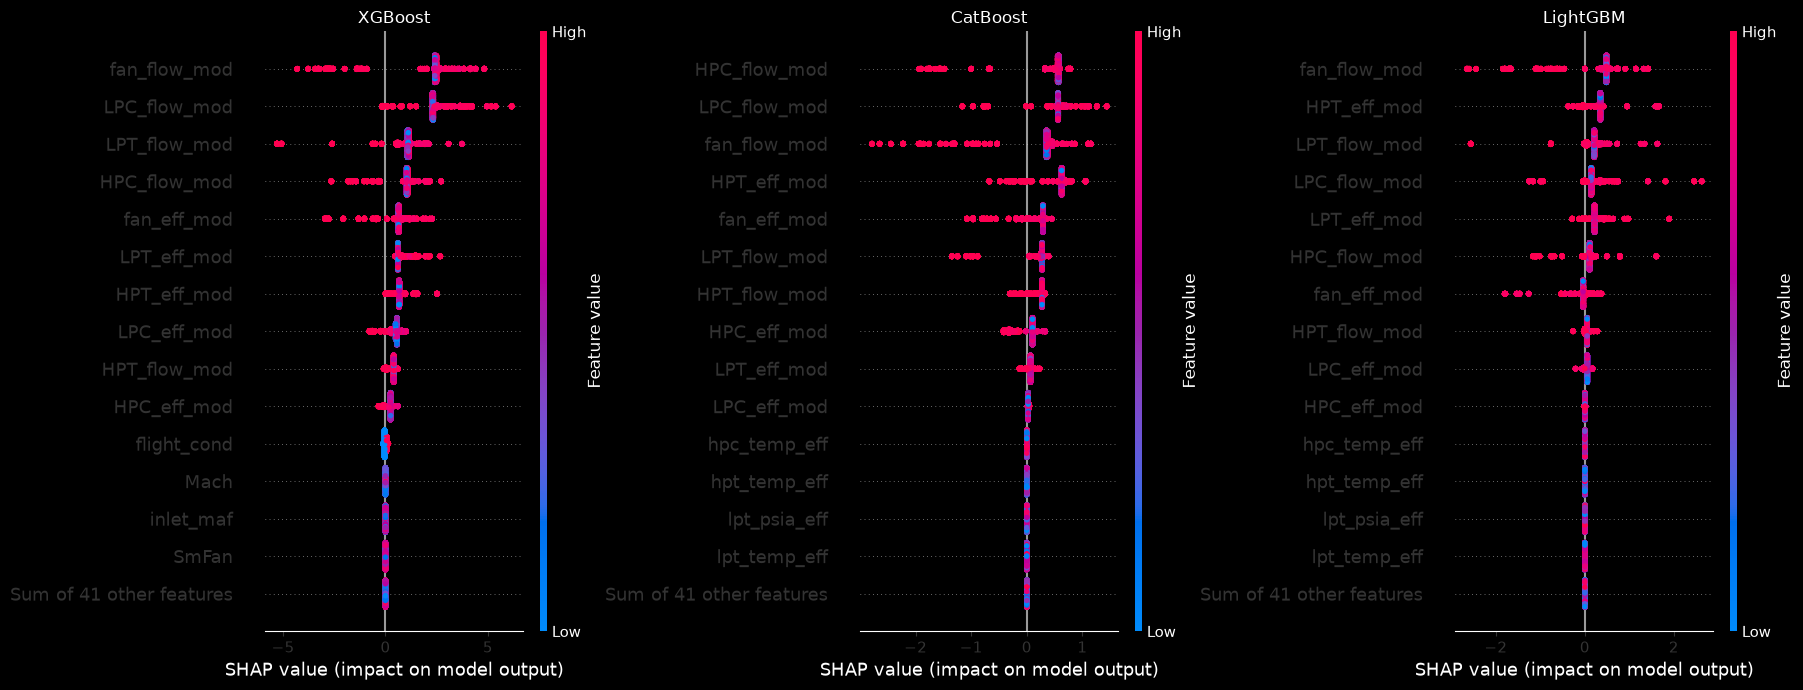

In [216]:
for name, t in tables.items():
    shdf = pd.DataFrame(t)
    shdf.to_csv(f'{name}SHAP.csv')

show_beeswarm(svals, xtest, mask)

# SHAP tables for remaining useful life

In [217]:
xtrain, xtest, ytrain, ytest, xtr, xval, ytr, yval, gtrain, rul_models = models('RUL')
tables, svals, mask = get_shap_tables(xtest, ytest, rul_models)

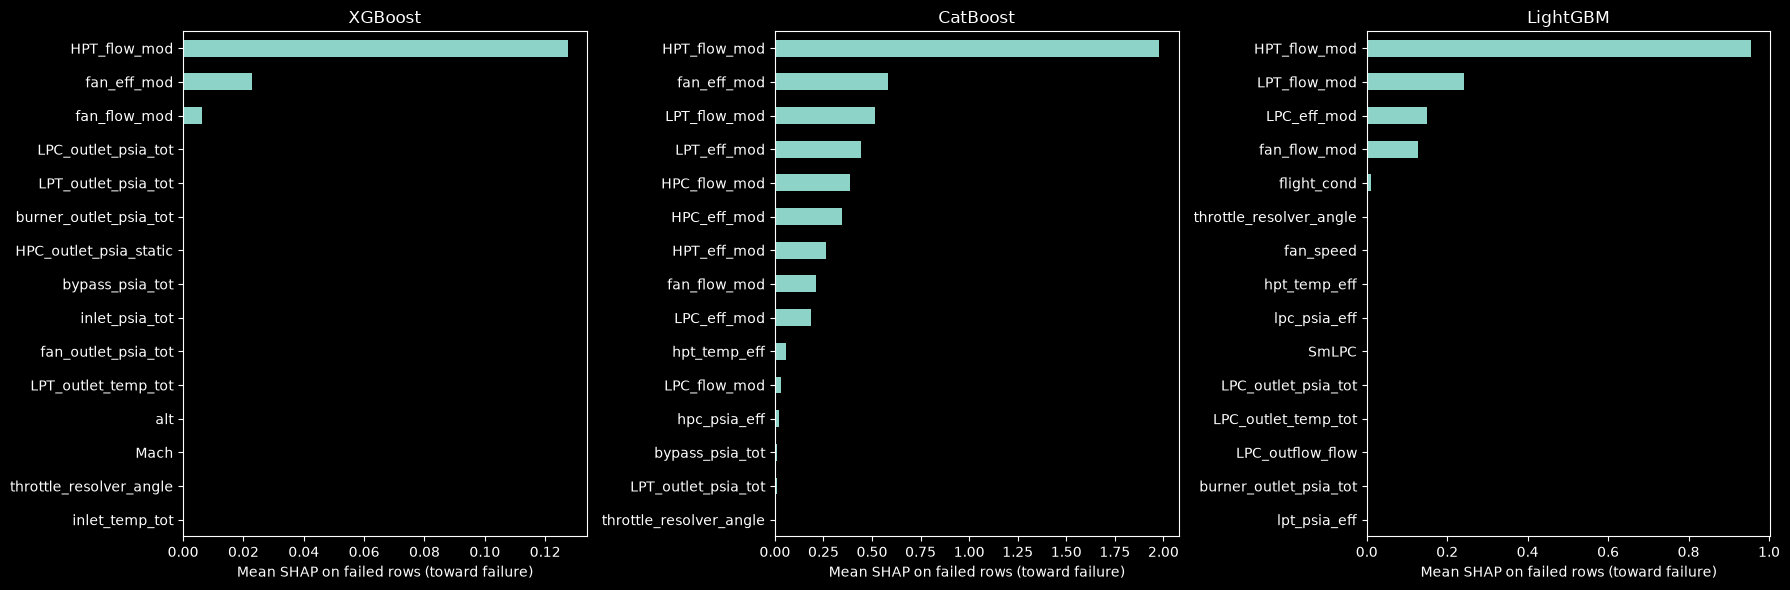

In [218]:
bar_plt = get_barplots(tables)

In [219]:
consensus_table_obj = consensus_table(tables)
consensus_df = pd.DataFrame(consensus_table_obj)
consensus_df

,XGBoost,CatBoost,LightGBM,avg_rank
HPT_flow_mod,1.0,1.0,1.0,1.000000
fan_flow_mod,3.0,8.0,4.0,5.000000
hpt_temp_eff,25.5,10.0,8.0,14.500000
throttle_resolver_angle,25.5,15.0,6.0,15.500000
LPT_flow_mod,50.0,3.0,2.0,18.333333
fan_eff_mod,2.0,2.0,52.0,18.666667
burner_outlet_psia_tot,25.5,17.0,14.0,18.833333
LPT_outlet_psia_tot,25.5,14.0,23.0,20.833333
HPT_outlet_flow,25.5,16.0,23.0,21.500000
LPC_eff_mod,53.0,9.0,3.0,21.666667


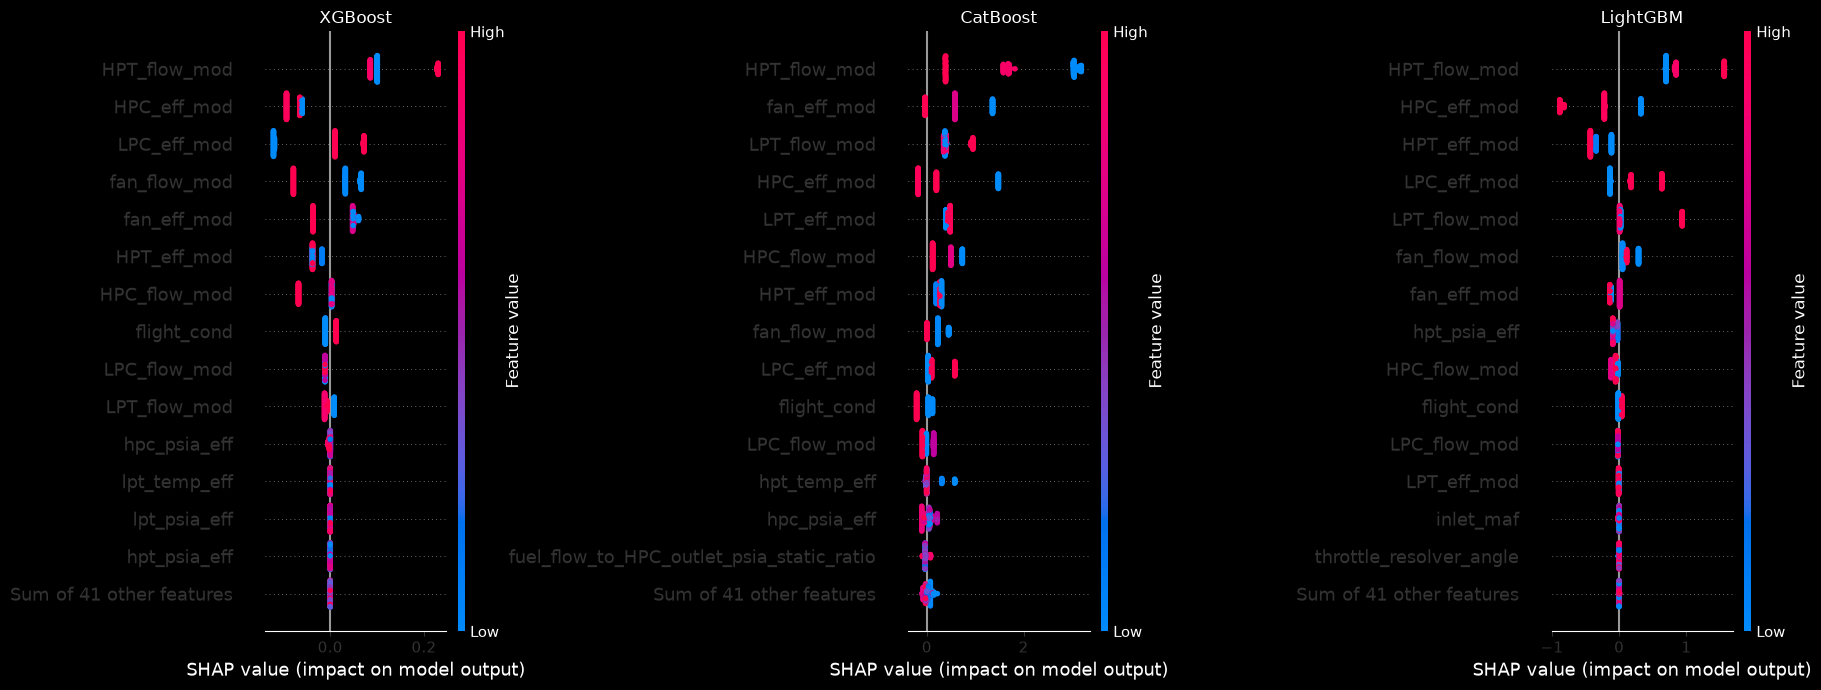

In [220]:
show_beeswarm(svals, xtest, mask)

# Feature Ablations on RUL
* The leak check argument drops all health status parameters, which requires the models to be retrained.
* A sharp drop in performance indicates that the parameters are leaking into the RUL label.
* No drop in performance indicates that they are redundant, or cause some error that hurts performance.

In [221]:
tree_based_ensemble(df, 'RUL', retrain=True, leak_check = True)
tree_based_ensemble(df, 'RUL', 'LightGBM', retrain=True, leak_check = True)
tree_based_ensemble(df, 'RUL', 'CatBoost', retrain=True, leak_check = True)

XGBoost saved as RULXGBoostmodel.json
XGBoost | Test PR_AUC=0.9993 | Test ROC_AUC=0.9571
LightGBM saved as RULLightGBMmodel.json
LightGBM | Test PR_AUC=0.9993 | Test ROC_AUC=0.9545
CatBoost saved as RULCatBoostmodel.json
CatBoost | Test PR_AUC=0.9989 | Test ROC_AUC=0.9348


{'model': CatBoostClassifier(eval_metric='AUC', learning_rate=0.1, n_estimators=76, random_seed=42, thread_count=4, verbose=0),
 'cv_scores': array([0.99732534, 0.99953488, 0.99870829, 0.99915022]),
 'yprob': array([0.98985839, 0.99193103, 0.99858041, ..., 0.95272066, 0.95116661,
        0.97373537], shape=(13374,)),
 'ytest': array([1, 1, 1, ..., 0, 0, 0], shape=(13374,)),
 'test_auc': 0.9989112277083404}

* With or without the provided mod_eff health parameters RUL is predicted suspiciously well. Other features may leak into RUL to some degree.
* Below the most important features (excluding health parameters) are reported.

In [222]:
model = xgb.XGBClassifier()
model.load_model("RULXGBoostmodel.json")

xtrain, xtest, ytrain, ytest, xtr, xval, ytr, yval, gtrain = preprocess_tree(df, "RUL", leak_check=True)

_, _, _, _, _, _, _, _, _, rul_models = models('RUL')

explainer = shap.TreeExplainer(model)
shap_vals = explainer.shap_values(xtest)
tables, svals, mask = get_shap_tables(xtest, ytest, rul_models)

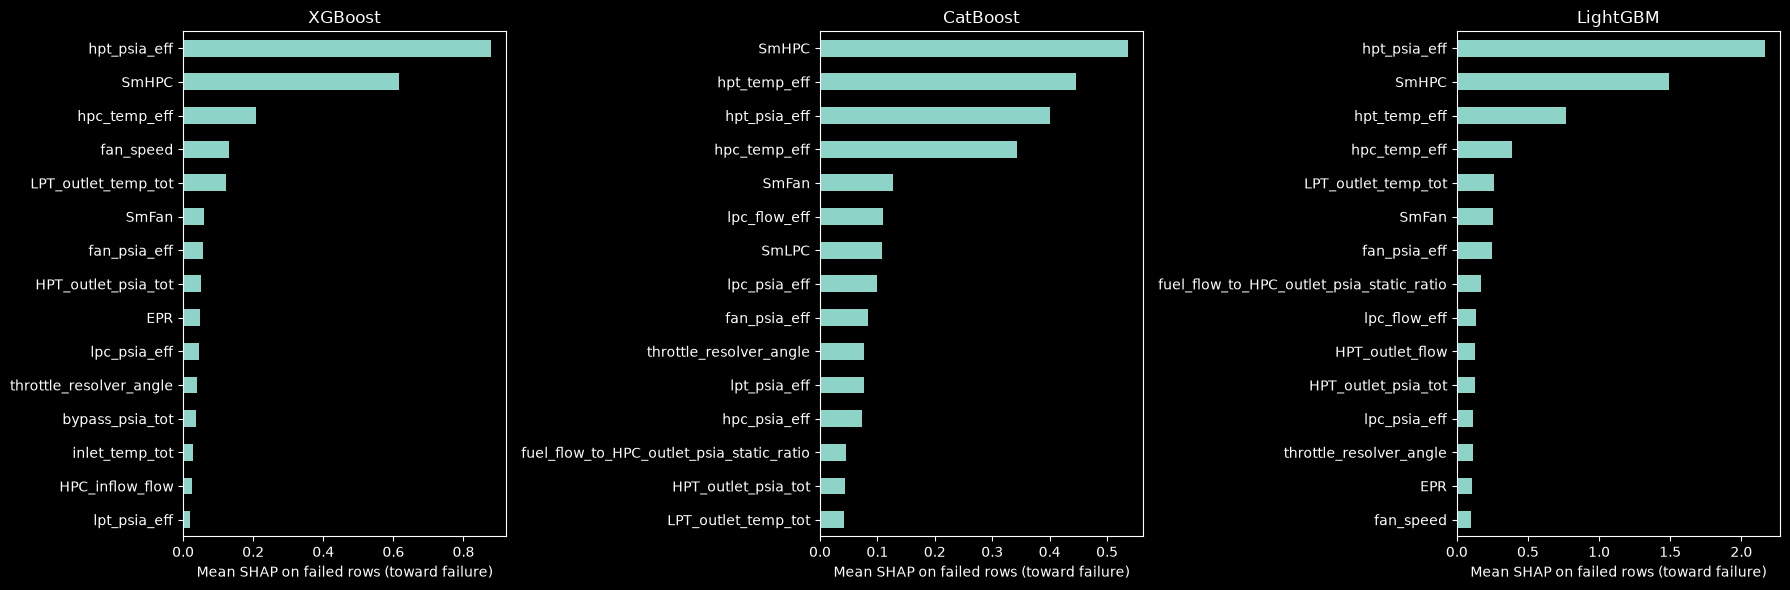

In [223]:
bar_plt = get_barplots(tables)

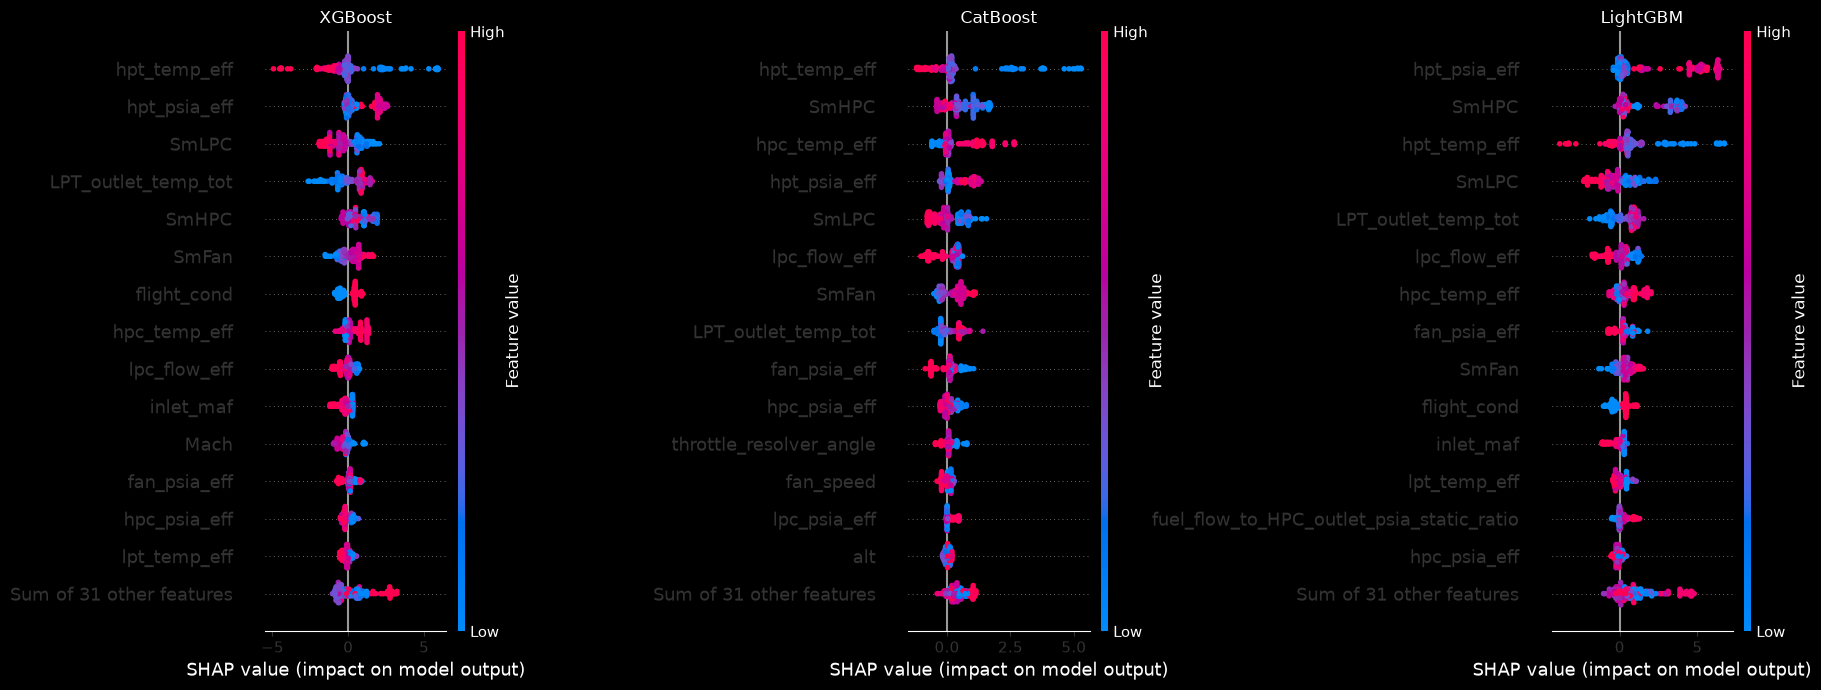

In [224]:
show_beeswarm(svals, xtest, mask)